## 1. 导入依赖

先在当前 Python 环境安装 requirements.txt 中的依赖，再从上到下运行全部单元。重启内核后也需要重新顺序运行。


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

## 2. 读取数据并查看完整光谱

将 SourceGratingTrans.csv 放在笔记本所在目录，并以该目录作为工作目录。Wavelength 是波长（nm），dBm 是对数光功率。检查缺失值后观察完整光谱，确定目标谷的位置。数据来源：[巴斯大学公开数据仓库](https://researchdata.bath.ac.uk/1662/)，Smith 与 Mosley（2026），DOI：10.15125/BATH-01662，许可：CC BY 4.0。


   Wavelength     dBm
0    1552.840 -75.177
1    1552.845 -75.226
2    1552.850 -75.194
3    1552.855 -75.178
4    1552.860 -75.202
Wavelength    0
dBm           0
dtype: int64
数据点数： 1201


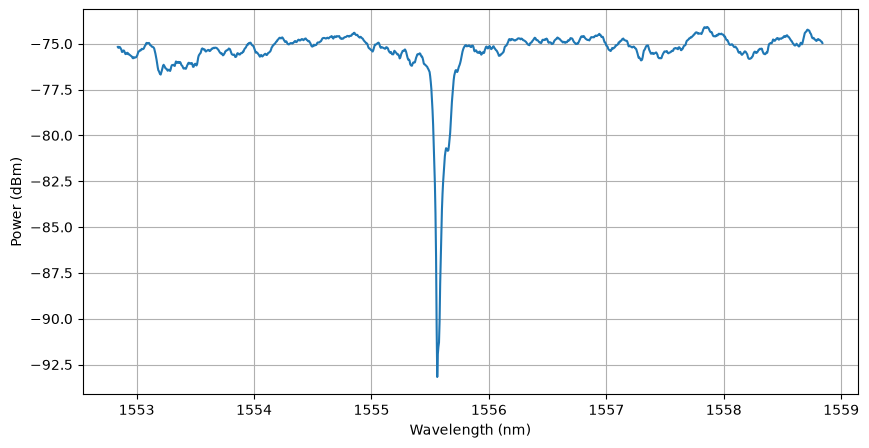

In [2]:
data = pd.read_csv(r'SourceGratingTrans.csv')

# 将两列转换为 NumPy 数组，便于索引、计算和拟合。
wavelength = data['Wavelength'].to_numpy()
power_dbm = data['dBm'].to_numpy()

plt.figure(figsize=(10,5))
plt.plot(wavelength, power_dbm)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Power (dBm)')
plt.grid()
plt.show()

print(data.head())       # 查看前5行
print(data.isna().sum()) # 查看每列缺失值数量
print("数据点数：", len(data))

## 3. 截取目标谷附近的波段

本例选择 1555.2–1555.9 nm。分析其他光谱时，需要先观察全谱，再调整范围。波长和功率必须使用同一个筛选条件，保持逐点对应；改变区间可能影响拟合结果。


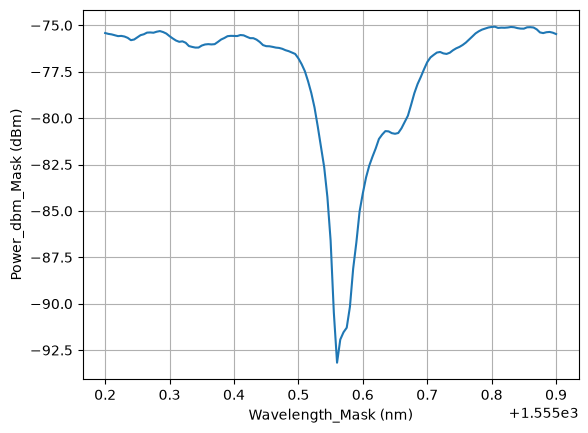

In [3]:
# & 表示两个条件同时成立；每个比较条件都需要括号。
mask = (wavelength >= 1555.2) & (wavelength <= 1555.9)
# 同一个 mask 同时用于两列，避免波长与功率错位。
wavelength_mask = wavelength[mask]
power_dbm_mask = power_dbm[mask]

plt.plot(wavelength_mask, power_dbm_mask)
plt.xlabel('Wavelength_Mask (nm)')
plt.ylabel('Power_dbm_Mask (dBm)')
plt.grid()
plt.show()

## 4. 用最低采样点估计中心

argmin 返回局部功率数组中最小值的索引，再用同一索引读取局部波长和功率。此结果受采样间隔与噪声影响，不是已知的真实中心。


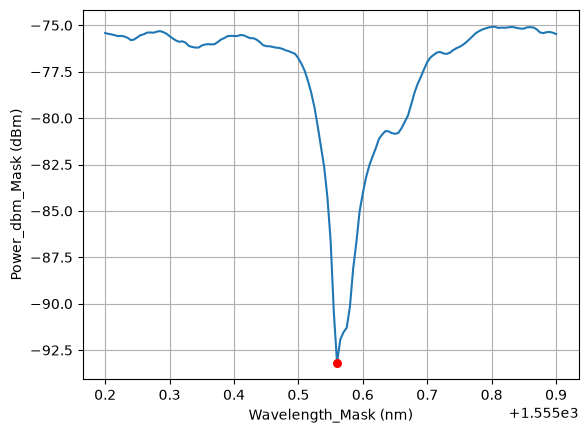

In [4]:
# 这里得到的是局部数组的索引，后续也要访问局部数组。
min_index = np.argmin(power_dbm_mask)
min_wavelength_mask = wavelength_mask[min_index]
min_power_dbm_mask = power_dbm_mask[min_index]

plt.plot(wavelength_mask, power_dbm_mask)
plt.scatter(min_wavelength_mask, min_power_dbm_mask,c = 'red',s = 30,zorder=10)
plt.xlabel('Wavelength_Mask (nm)')
plt.ylabel('Power_dbm_Mask (dBm)')
plt.grid()
plt.show()

## 5. 用高斯谷模型拟合

这是对 dBm 曲线的经验拟合，并非完整的 FBG 物理模型。模型参数依次为背景 b（dBm）、谷深 A（dB）、中心 c（nm）、宽度参数 w（nm）。w 不是半高全宽。初始猜测按同一顺序传入；当前代码未设置参数边界，需要检查拟合结果是否合理。实际谷形不对称，因此对称高斯模型可能存在系统性偏差。


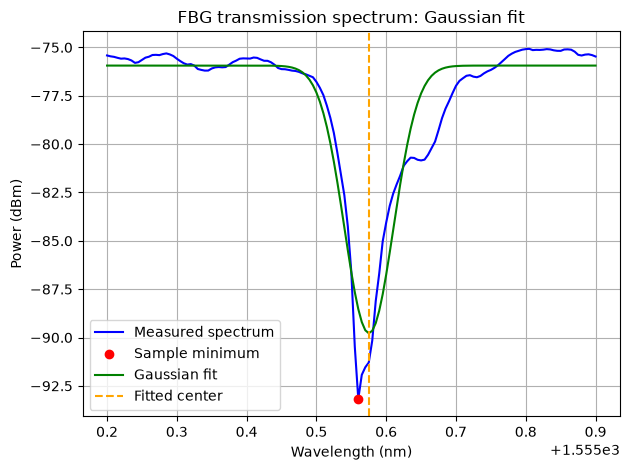

In [5]:
def gaussian_dip(wavelength, b,A,c,w):
    # 在 wavelength == c 时，模型值为 b - A。
    return b - A*np.exp(-((wavelength-c)/w)**2)

# p 的顺序为 [b, A, c, w]；cov 是参数协方差的估计矩阵。
# p0 中心采用最低点波长；初始宽度为 0.1 nm。
p,cov = curve_fit(gaussian_dip,wavelength_mask,power_dbm_mask,p0 = [-75,18,min_wavelength_mask,0.1])
# 使用全部四个拟合参数，在同一组局部波长上计算预测值。
y =gaussian_dip(wavelength_mask,p[0],p[1],p[2],p[3])

plt.plot(wavelength_mask, power_dbm_mask,
         color="blue", label="Measured spectrum")

plt.scatter(min_wavelength_mask, min_power_dbm_mask,
            color="red", zorder=5, label="Sample minimum")

plt.plot(wavelength_mask, y,
         color="green", label="Gaussian fit")

plt.axvline(p[2], color="orange", linestyle="--",
            label="Fitted center")

plt.xlabel("Wavelength (nm)")
plt.ylabel("Power (dBm)")
plt.title("FBG transmission spectrum: Gaussian fit")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

## 6. 计算残差与中心差值

残差定义为测量值减拟合值，两个 dBm 值相减得到的差值单位为 dB。中心差值取绝对值，并由 nm 换算为 pm。没有精确真值，因此方法间差异不能称为定位误差，也不能据此判断哪种方法更准确。输出小数位不代表测量精度。


In [6]:
# 两个数组在相同波长位置逐点相减。
residual =power_dbm_mask - y
center_fit = p[2]
# 1 nm = 1000 pm；这里是方法间差异，不是真值误差。
difference_pm = np.abs(center_fit - min_wavelength_mask)*1000

print(f"最低点法中心：{min_wavelength_mask:.6f} nm")
print(f"拟合法中心：{center_fit:.6f} nm")
print(f"两种方法的差值：{difference_pm:.3f} pm")

最低点法中心：1555.560000 nm
拟合法中心：1555.575272 nm
两种方法的差值：15.272 pm


## 7. 检查残差图

零线表示测量值与拟合值相等；正残差表示测量值较高，负残差表示测量值较低。连续波峰、波谷等规律说明模型未充分描述数据。本例谷底和右侧肩部的偏差应纳入结论，不能仅以拟合成功作为模型适合的依据。


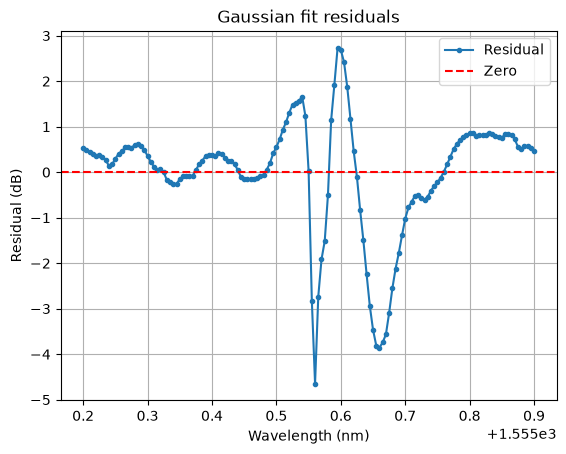

In [7]:
plt.plot(wavelength_mask,residual, '.-', label='Residual')
plt.axhline(0, color='red', linestyle='--', label='Zero')
plt.xlabel('Wavelength (nm)')
plt.ylabel('Residual (dB)')
plt.title('Gaussian fit residuals')
plt.legend()
plt.grid()
plt.show()

## 8. 拟合区间敏感性分析

复用前面读取的完整数据、gaussian_dip 函数和最低点波长。固定模型及初始猜测，只改变参与拟合的波长区间，观察中心估计是否依赖区间选择。第一组与原始范围相同，用于核对结果。结果表中的 change_pm 以原高斯中心 center_fit 为参考，正值表示向长波移动，负值表示向短波移动。


In [8]:
# 保存原高斯拟合中心作为基准，不改变前面分析的变量。
reference_center = center_fit
fit_ranges = [(1555.20,1555.90),(1555.30,1555.80),(1555.40,1555.75)]
results = []

# 每组都从完整数据重新截取，再拟合，最后保存当前参数。
for lower,upper in fit_ranges:
    mask_current = (wavelength >= lower) & (wavelength <= upper)
    wavelength_current = wavelength[mask_current]
    power_current = power_dbm[mask_current]
    # 单独保存当前协方差，避免覆盖原始拟合的 cov。
    p_current,cov_current = curve_fit(gaussian_dip,wavelength_current,power_current,p0 = [-75,18,min_wavelength_mask,0.1])
    # copy() 保存独立的参数副本，供后面分别绘图。
    results.append({
    'lower': lower,
    'upper': upper,
    'points': len(wavelength_current),
    'center_nm': p_current[2],
    'change_pm': (p_current[2] - reference_center) * 1000,
    'params': p_current.copy()
     })
    print(f"范围：{lower}～{upper} nm，点数：{len(wavelength_current)}")


results_table = pd.DataFrame(results)
# 这里只在展示时隐藏参数数组；results 中仍保留完整参数。
display(results_table.drop(columns="params"))


范围：1555.2～1555.9 nm，点数：141
范围：1555.3～1555.8 nm，点数：101
范围：1555.4～1555.75 nm，点数：71


,lower,upper,points,center_nm,change_pm
0,1555.2,1555.90,141,1555.575272,0.000000
1,1555.3,1555.80,101,1555.574025,-1.247136
2,1555.4,1555.75,71,1555.572735,-2.537652


### 不同区间的拟合曲线对比

背景测量光谱沿用原来的较宽区间。逐条取出已保存的参数，在对应拟合范围内计算曲线，不把曲线延伸到未参与拟合的波段。


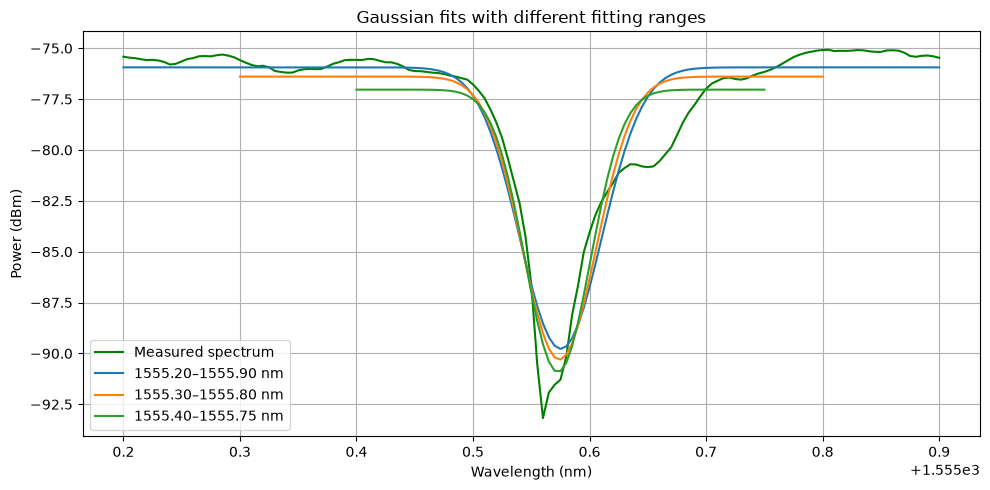

In [9]:
plt.figure(figsize=(10,5))

plt.plot(wavelength_mask, power_dbm_mask,c = 'g',label ='Measured spectrum')

for result in results:
    mask_plot = (wavelength >= result['lower']) & (wavelength <= result['upper'])
    x_plot = wavelength[mask_plot]
    # 每条曲线必须使用当前记录自己的 [b, A, c, w]。
    params = result['params']
    y_plot = gaussian_dip(x_plot, params[0], params[1], params[2], params[3])
    plt.plot(x_plot, y_plot,label=f'{result["lower"]:.2f}–{result["upper"]:.2f} nm')

plt.xlabel("Wavelength (nm)")
plt.ylabel("Power (dBm)")
plt.title("Gaussian fits with different fitting ranges")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

## 区间敏感性分析结论

在三组拟合区间下，高斯拟合中心分别为 1555.575272、1555.574025 和 1555.572735 nm，最大与最小中心相差约 2.538 pm。相对原来的较宽区间，另外两组中心分别向短波方向移动约 1.247 和 2.538 pm。

结果说明，中心估计会受到拟合区间选择的影响。三组拟合曲线仍未充分描述实际光谱的尖锐谷底及右侧肩部，表明对称高斯模型存在局限。本实验仅考察上述三个区间，中心变化范围不代表定位误差或测量不确定度，也不能据此判断哪一组中心更准确。


## 9. 局部二次拟合

前面的高斯模型描述整个局部谷形；这里仅用谷底附近的数据拟合抛物线，估计局部最低位置。继续使用原来的 wavelength_mask、power_dbm_mask 和 min_index；min_index 是局部数组的索引，不能直接用来索引完整光谱。

先选最低点左右各 5 个点，共 11 个点。Python 切片包含起点、不包含终点，因此右边界写为 min_index + 6。当前示例谷底两侧有足够数据；换数据或扩大窗口前，应检查 start >= 0 且 stop <= len(wavelength_mask)，否则切片可能截错或点数不足。


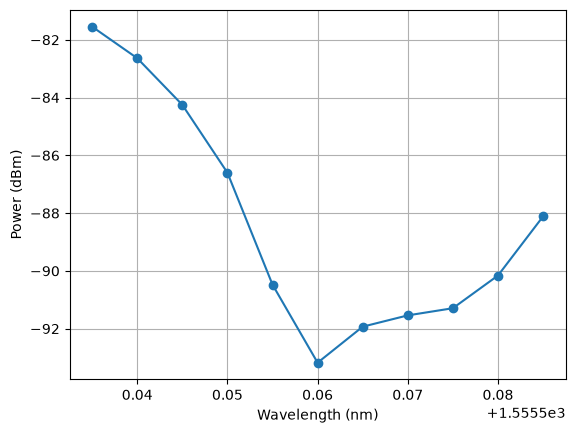

In [10]:
start = min_index-5
stop = min_index +6
wavelength_quad = wavelength_mask[start:stop]
power_quad = power_dbm_mask[start:stop]

plt.figure()
plt.plot(wavelength_quad, power_quad, "o-")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Power (dBm)")
plt.grid()
plt.show()

### 用相对波长拟合抛物线

定义 u = 波长 − 最低采样点波长，使自变量位于零附近，改善数值尺度。np.polyfit(u, power_quad, 2) 按降幂返回 [a, b, d]，对应 P(u) = a·u² + b·u + d。这里直接拟合 dBm 数据，属于局部经验近似，不能用来解释完整光栅物理参数。


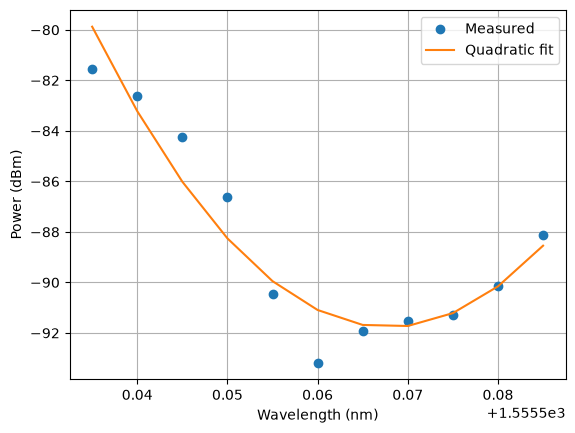

In [11]:
u = wavelength_quad - min_wavelength_mask
# 2 表示二次多项式，返回值依次是二次项、一次项和常数项系数。
p_quad = np.polyfit(u,power_quad,2)
a_quad, b_quad, d_quad = p_quad
power_fit_quad = a_quad*u**2 + b_quad*u + d_quad

plt.figure()
plt.plot(wavelength_quad, power_quad, "o", label="Measured")
plt.plot(wavelength_quad, power_fit_quad, "-", label="Quadratic fit")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Power (dBm)")
plt.legend()
plt.grid()
plt.show()

### 由顶点估计局部最低位置

抛物线顶点的相对位置为 −b/(2a)，加回参考波长后得到 center_quad（nm）；p_vertex 是该顶点处的模型功率（dBm）。此单元仅计算顶点，尚未自动检查有效性；需要 a > 0 且顶点位于拟合范围内，才能将其作为局部最低位置的候选估计。a = 0 时顶点公式不适用。


In [12]:
u_vertex = - b_quad/(2*a_quad)
# 将相对位置还原为绝对波长。
center_quad = min_wavelength_mask + u_vertex
p_vertex = a_quad * u_vertex**2 + b_quad * u_vertex + d_quad

### 改变邻域点数，检查顶点稳定性

windows 中的 n 表示最低点左右各取 n 个点，包含最低点时总数应为 2n+1。本例依次使用 7、11、17 个点，每次都重新拟合。shift_pm 以最低采样点波长为参考（与上面的高斯区间实验参考不同），单位为 pm。opens_up 检查开口向上，vertex_in_range 检查顶点在窗口内；这两项只是基本检查，不保证模型适合或结果准确。当前代码假定系数非零且邻域数据充足，处理其他数据时需另加边界、有限值和退化拟合检查。


In [13]:
windows = [3,5,8]
quad_results = []

for n in windows:
    new_start = min_index-n
    # 切片右端不包含在内，+1 才能包含最右侧的第 n 个点。
    new_stop = min_index +n+1
    new_wavelength_quad = wavelength_mask[new_start:new_stop]
    new_power_quad = power_dbm_mask[new_start:new_stop]
    new_u = new_wavelength_quad - min_wavelength_mask
    new_a, new_b, new_d = np.polyfit(new_u, new_power_quad, 2)
    new_u_vertex = -new_b / (2 * new_a)
    new_center_quad = min_wavelength_mask + new_u_vertex
    # 保存结果和基本有效性标志，供后面的汇总表筛选。
    quad_results.append({
        "half_window": n,
        "points": len(new_wavelength_quad),
        "center_nm": new_center_quad,
        "shift_pm": (new_center_quad - min_wavelength_mask) * 1000,
        "opens_up": bool(new_a > 0),
        "vertex_in_range": bool(
            new_wavelength_quad.min()
            <= new_center_quad
            <= new_wavelength_quad.max()
        )
    })
    print(f"左右各取 {n} 个点，顶点波长：{new_center_quad:.6f} nm")
quad_table = pd.DataFrame(quad_results)
display(quad_table)

左右各取 3 个点，顶点波长：1555.565765 nm
左右各取 5 个点，顶点波长：1555.567875 nm
左右各取 8 个点，顶点波长：1555.568413 nm


,half_window,points,center_nm,shift_pm,opens_up,vertex_in_range
0,3,7,1555.565765,5.765144,True,True
1,5,11,1555.567875,7.875276,True,True
2,8,17,1555.568413,8.412707,True,True


### 汇总三类位置估计

最低点法给出最低采样点的位置；高斯拟合给出最佳拟合对称谷形的中心；局部二次拟合给出谷底邻域抛物线的顶点。三者含义不同，在不对称光谱上不必重合。表中的 shift_pm 全部相对最低采样点计算，不是相对真实中心的误差。未通过开口和顶点范围检查的二次结果仍可在上一张表查看，但不纳入本汇总。没有精确真值，不能仅根据差值大小给方法排准确度名次。


In [14]:
# 先记录最低点法和原始区间的高斯拟合结果
summary_rows = [
    {
        "method": "Sample minimum",
        "center_nm": min_wavelength_mask,
        "shift_pm": 0.0
    },
    {
        "method": "Gaussian fit (1555.20–1555.90 nm)",
        "center_nm": center_fit,
        "shift_pm": (center_fit - min_wavelength_mask) * 1000
    }
]

# 只汇总通过两项基本检查的二次拟合结果
for row in quad_results:
    if row["opens_up"] and row["vertex_in_range"]:
        summary_rows.append({
            "method": f'Quadratic fit (±{row["half_window"]} points)',
            "center_nm": row["center_nm"],
            "shift_pm": row["shift_pm"]
        })

summary_table = pd.DataFrame(summary_rows)
display(summary_table)

,method,center_nm,shift_pm
0,Sample minimum,1555.560000,0.000000
1,Gaussian fit (1555.20–1555.90 nm),1555.575272,15.272433
2,Quadratic fit (±3 points),1555.565765,5.765144
3,Quadratic fit (±5 points),1555.567875,7.875276
4,Quadratic fit (±8 points),1555.568413,8.412707


## 10. 导出图片和结果表

以下单元复用前面的分析结果，将三张图片和三份 CSV 保存到项目的 results 文件夹。必须先按顺序运行前面的单元；重新运行会覆盖同名结果文件。


结果已保存到： D:\fbg-spectrum-dip-fitting\results


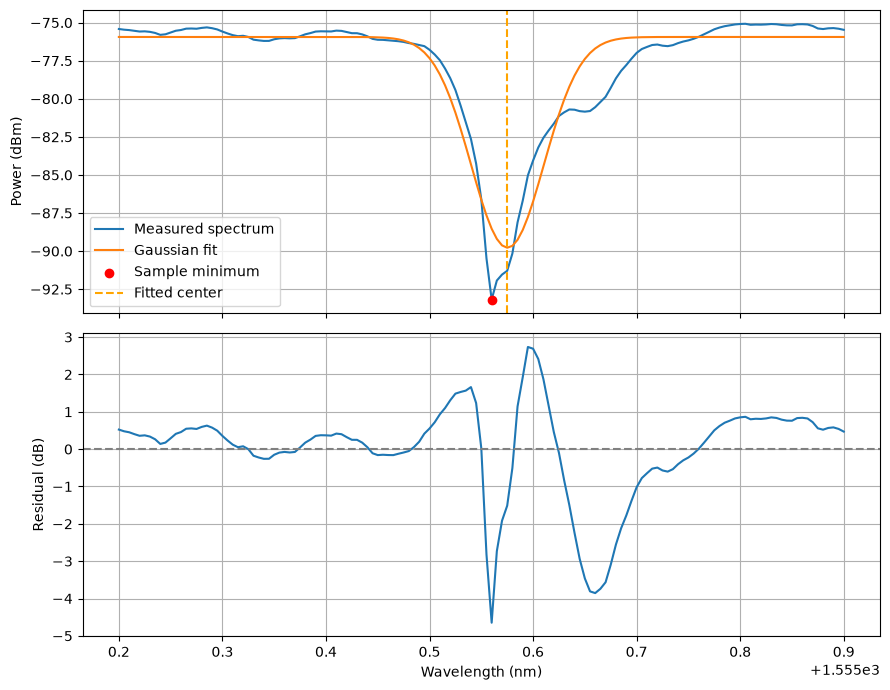

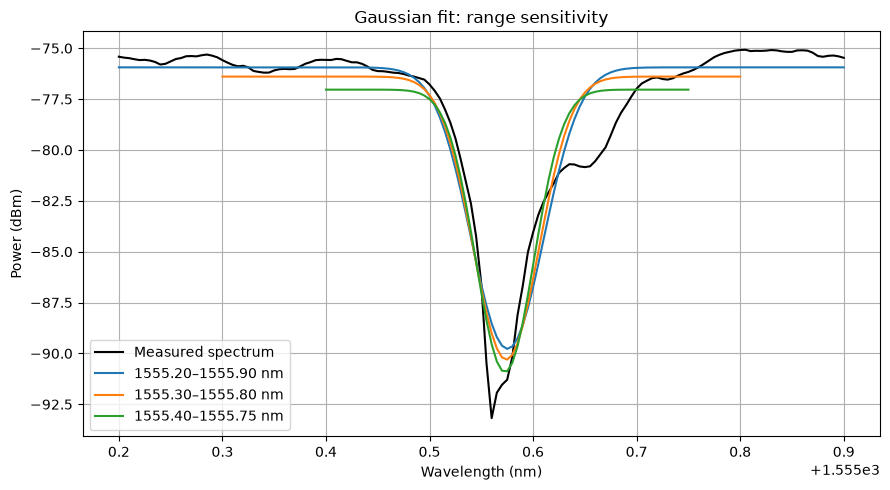

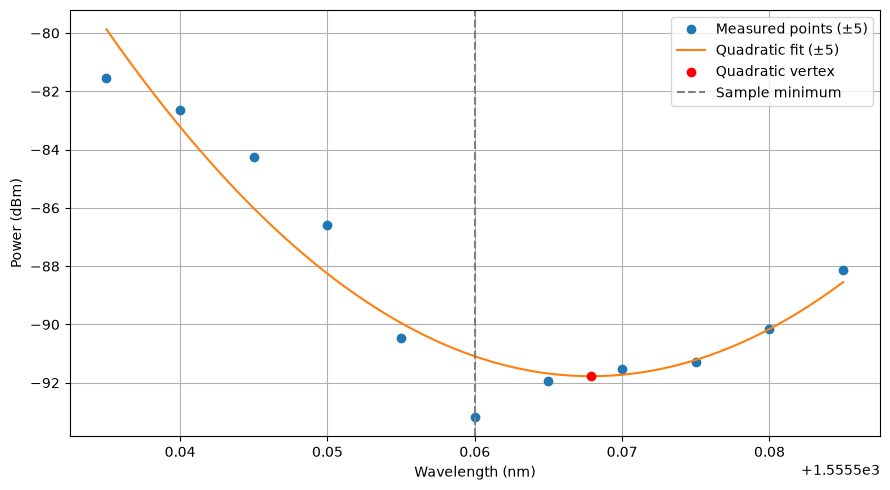

In [15]:
from pathlib import Path

# 在项目内集中保存结果；重新运行会更新这些文件。
output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

# 表格使用 UTF-8 BOM 编码，方便用常见表格软件打开。
summary_table.to_csv(output_dir / "method_comparison.csv", index=False, encoding="utf-8-sig")
results_table.drop(columns="params").to_csv(output_dir / "gaussian_range_sensitivity.csv", index=False, encoding="utf-8-sig")
quad_table.to_csv(output_dir / "quadratic_window_sensitivity.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].plot(wavelength_mask, power_dbm_mask, label="Measured spectrum")
axes[0].plot(wavelength_mask, y, label="Gaussian fit")
axes[0].scatter(min_wavelength_mask, min_power_dbm_mask, color="red", label="Sample minimum", zorder=5)
axes[0].axvline(center_fit, color="orange", linestyle="--", label="Fitted center")
axes[0].set_ylabel("Power (dBm)")
axes[0].legend()
axes[1].plot(wavelength_mask, residual)
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set_xlabel("Wavelength (nm)")
axes[1].set_ylabel("Residual (dB)")
for axis in axes:
    axis.grid()
fig.tight_layout()
fig.savefig(output_dir / "gaussian_fit_residuals.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(wavelength_mask, power_dbm_mask, color="black", label="Measured spectrum")
for result in results:
    selection = (wavelength >= result["lower"]) & (wavelength <= result["upper"])
    x_range = wavelength[selection]
    ax.plot(x_range, gaussian_dip(x_range, *result["params"]),
            label=f'{result["lower"]:.2f}–{result["upper"]:.2f} nm')
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Power (dBm)")
ax.set_title("Gaussian fit: range sensitivity")
ax.legend()
ax.grid()
fig.tight_layout()
fig.savefig(output_dir / "gaussian_range_sensitivity.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(wavelength_quad, power_quad, "o", label="Measured points (±5)")
# 使用更密的横坐标展示抛物线；这不会增加新的测量数据。
u_dense = np.linspace(u.min(), u.max(), 300)
ax.plot(u_dense + min_wavelength_mask, np.polyval(p_quad, u_dense), label="Quadratic fit (±5)")
ax.scatter(center_quad, p_vertex, color="red", label="Quadratic vertex", zorder=5)
ax.axvline(min_wavelength_mask, color="gray", linestyle="--", label="Sample minimum")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Power (dBm)")
ax.legend()
ax.grid()
fig.tight_layout()
fig.savefig(output_dir / "quadratic_local_fit.png", dpi=180)
plt.show()

print("结果已保存到：", output_dir.resolve())
